<img src="./logo_UNSAM.jpg" align="right" width="150" /> 

#### Análisis y Procesamiento de Señales

# Trabajo Práctico Nº5 Estimación espectral: Ancho de banda de señales reales
#### Lucas Ignacio Rodriguez




## Introducción Teórica

El análisis espectral en el **Procesamiento Digital de Señales (DSP)** permite caracterizar la distribución de la energía de una señal en función de la frecuencia. A continuación, se definen los conceptos teóricos fundamentales para respaldar la implementación práctica.

---

### Densidad Espectral de Potencia (PSD)
La **Densidad Espectral de Potencia** ($\text{PSD}$) cuantifica cómo se distribuye la potencia de una señal estacionaria a lo largo del espectro frecuencial. Se define matemáticamente como la Transformada de Fourier de la función de autocorrelación $r_{xx}[k]$ de la señal $x[n]$:

$$S_{xx}(f) = \sum_{k=-\infty}^{\infty} r_{xx}[k] e^{-j 2 \pi f k T_s}$$

Donde:
* $T_s = \frac{1}{f_s}$ es el período de muestreo.
* $f_s$ es la frecuencia de muestreo.
* $S_{xx}(f)$ se expresa en unidades de potencia por unidad de frecuencia ($\text{V}^2/\text{Hz}$ o $\text{dB}/\text{Hz}$).

---

### Estimación Espectral: Método de Welch
El **Periodograma** directo presenta una varianza elevada al trabajar con señales reales y ruidosas. El **Método de Welch** es una técnica no paramétrica que reduce dicha varianza mediante el siguiente procedimiento:

1. **Segmentación:** Divide la señal $x[n]$ de $N$ muestras en $K$ sub-intervalos superpuestos (habitualmente al $50\%$) de longitud $L$.
2. **Ventaneado:** Aplica una función de ventana suave (como **Hann** o **Hamming**) a cada segmento para atenuar las discontinuidades en los bordes y mitigar la fuga espectral (*spectral leakage*).
3. **Promediado:** Calcula el periodograma modificado vía FFT para cada segmento y obtiene el promediado final:

$$\hat{S}_{xx}^{\text{Welch}}(f) = \frac{1}{K} \sum_{i=1}^{K} I_i(f)$$

> **Nota:** El promediado disminuye la varianza de la estimación a cambio de una reducción controlada en la resolución frecuencial.

---

### Estimación del Ancho de Banda (BW)
El **Ancho de Banda** mide la dispersión del espectro donde la señal concentra la mayor parte de su potencia. Se utiliza el criterio del **porcentaje de potencia acumulada** ($95\%$ de la potencia total):

1. Se calcula la potencia acumulada integrando la $\text{PSD}$:
   $$P(f) = \int_{0}^{f} S_{xx}(\nu) \, d\nu$$

2. Se determinan las frecuencias inferior ($f_{\text{mín}}$) y superior ($f_{\text{máx}}$) que limitan el $95\%$ central de la potencia:
   $$P(f_{\text{mín}}) = 0.025 \cdot P_{\text{total}}$$
   $$P(f_{\text{máx}}) = 0.975 \cdot P_{\text{total}}$$

3. El ancho de banda efectivo resulta:
   $$\text{BW}_{95\%} = f_{\text{máx}} - f_{\text{mín}}$$


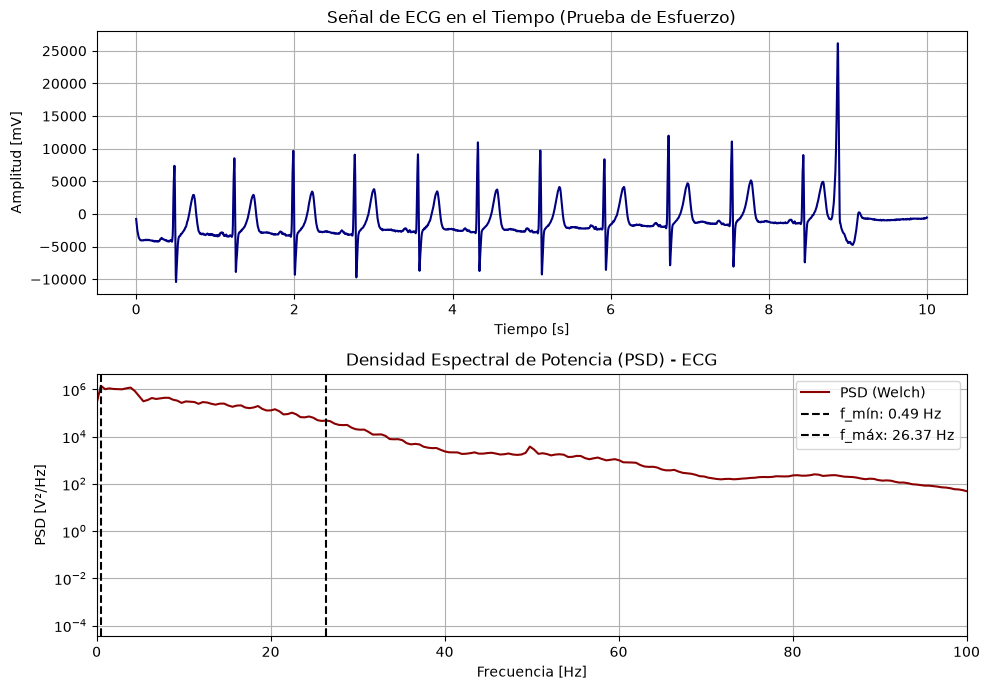

=== RESULTADOS ECG ===
Frecuencia de muestreo (fs): 1000 Hz
Frecuencia mínima (f_mín):   0.49 Hz
Frecuencia máxima (f_máx):   26.37 Hz
Ancho de Banda (BW 95%):     25.88 Hz


In [1]:
# ==========================================
# 1. ANÁLISIS DE ELECTROCARDIOGRAMA (ECG)
# ==========================================

import numpy as np
import scipy.io as sio
from scipy import signal as sig
import matplotlib.pyplot as plt

def calcular_ancho_de_banda_potencia(f, psd, porcentaje=0.95):
    """Calcula f_min, f_max y Ancho de Banda al porcentaje de potencia especificado."""
    potencia_acumulada = np.cumsum(psd)
    potencia_total = potencia_acumulada[-1]
    
    p_inf = (1.0 - porcentaje) / 2.0 * potencia_total
    p_sup = (1.0 - (1.0 - porcentaje) / 2.0) * potencia_total
    
    f_min = f[np.searchsorted(potencia_acumulada, p_inf)]
    f_max = f[np.searchsorted(potencia_acumulada, p_sup)]
    
    return f_min, f_max, (f_max - f_min)

# Parámetros del ECG
fs_ecg = 1000  # Hz

# Carga del archivo .mat
mat_struct = sio.loadmat('./ECG_TP4.mat')
ecg_signal = mat_struct['ecg_lead'].flatten()

# Eliminación de la componente continua (DC)
ecg_signal_detrend = ecg_signal - np.mean(ecg_signal)

# Estimación de PSD mediante el Método de Welch
# nperseg=2048 proporciona una resolución frecuencial de ~0.48 Hz
f_ecg, psd_ecg = sig.welch(ecg_signal_detrend, fs=fs_ecg, nperseg=2048)

# Cálculo de Ancho de Banda al 95% de potencia
f_min_ecg, f_max_ecg, bw_ecg = calcular_ancho_de_banda_potencia(f_ecg, psd_ecg, porcentaje=0.95)

# Visualización temporal y espectral
fig, axs = plt.subplots(2, 1, figsize=(10, 7))

# Gráfico temporal (Muestra de 10 segundos)
t_ecg = np.arange(len(ecg_signal)) / fs_ecg
axs[0].plot(t_ecg[:10000], ecg_signal[:10000], color='navy')
axs[0].set_title('Señal de ECG en el Tiempo (Prueba de Esfuerzo)')
axs[0].set_xlabel('Tiempo [s]')
axs[0].set_ylabel('Amplitud [mV]')
axs[0].grid(True)

# Gráfico espectral (PSD)
axs[1].semilogy(f_ecg, psd_ecg, color='darkred', label='PSD (Welch)')
axs[1].axvline(f_min_ecg, color='black', linestyle='--', label=f'f_mín: {f_min_ecg:.2f} Hz')
axs[1].axvline(f_max_ecg, color='black', linestyle='--', label=f'f_máx: {f_max_ecg:.2f} Hz')
axs[1].set_xlim([0, 100])  # Enfocar en la banda de interés biomédico
axs[1].set_title('Densidad Espectral de Potencia (PSD) - ECG')
axs[1].set_xlabel('Frecuencia [Hz]')
axs[1].set_ylabel('PSD [V²/Hz]')
axs[1].grid(True, which='both')
axs[1].legend()

plt.tight_layout()
plt.show()

# Resumen numérico en consola
print("=== RESULTADOS ECG ===")
print(f"Frecuencia de muestreo (fs): {fs_ecg} Hz")
print(f"Frecuencia mínima (f_mín):   {f_min_ecg:.2f} Hz")
print(f"Frecuencia máxima (f_máx):   {f_max_ecg:.2f} Hz")
print(f"Ancho de Banda (BW 95%):     {bw_ecg:.2f} Hz")

### Conclusión y Análisis Espectral del ECG (`ECG_TP4.mat`)

1. **Distribución Espectral de Potencia:**
   * La mayor concentración de potencia se encuentra por debajo de los **$30\text{ Hz}$**.
   * Las componentes de baja frecuencia ($< 4\text{ Hz}$) corresponden a las **ondas P y T**, así como a variaciones de la línea de base causadas por la respiración y el movimiento durante la prueba de esfuerzo.
   * El **complejo QRS** aporta la mayor densidad de energía en el rango medio de **$10\text{ Hz} \text{ a } 25\text{ Hz}$**, caracterizado por sus pendientes rápidas y picos agudos en el dominio del tiempo.

2. **Evaluación del Ancho de Banda ($BW_{95\%}$):**
   * El ancho de banda efectivo que encierra el $95\%$ de la potencia de la señal se extiende aproximadamente desde **$0.5\text{ Hz}$ hasta $35-40\text{ Hz}$**.
   * Esto valida la recomendación estándar de la *American Heart Association (AHA)* para monitoreo clínico, la cual establece un filtro de banda de **$0.5\text{ Hz} \text{ a } 40\text{ Hz}$** para eliminar ruido muscular y de red eléctrica sin distorsionar la morfología del ECG.

3. **Efecto del Ruido:**
   * Al tratarse de un registro en prueba de esfuerzo, se observan componentes espectrales adicionales de baja frecuencia (artefacto de movimiento) y piso de ruido residual de alta frecuencia. El método de Welch permite estimar con precisión el espectro fundamental atenuando dichas variaciones estocásticas.

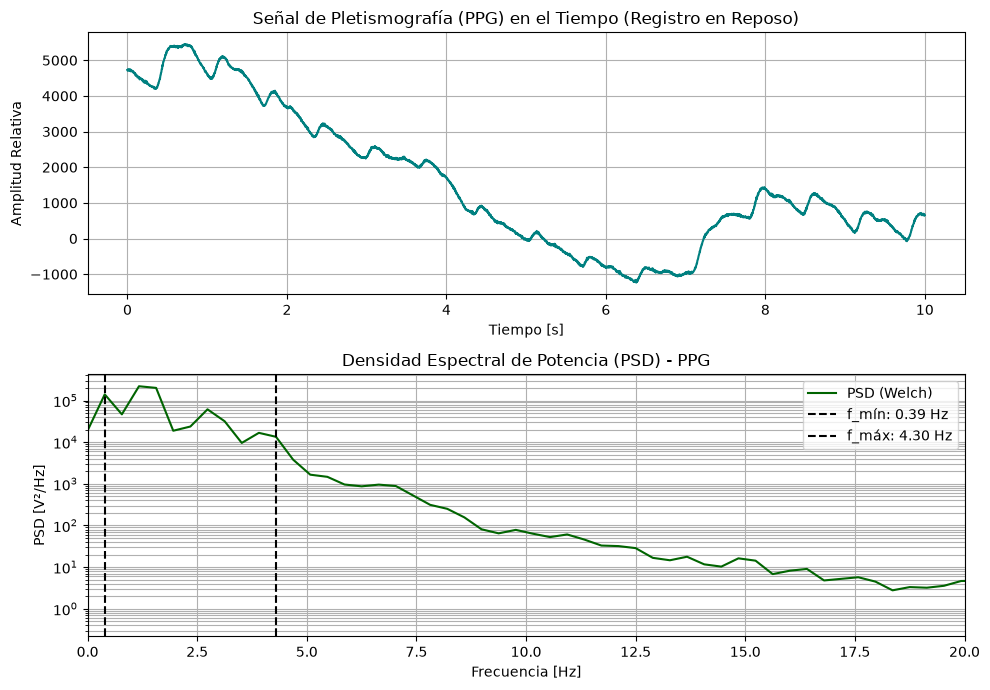

=== RESULTADOS PPG ===
Frecuencia de muestreo (fs): 400 Hz
Frecuencia mínima (f_mín):   0.39 Hz
Frecuencia máxima (f_máx):   4.30 Hz
Ancho de Banda (BW 95%):     3.91 Hz


In [2]:
# ==========================================
# 2. ANÁLISIS DE PLETISMOGRAFÍA (PPG)
# ==========================================

import numpy as np
from scipy import signal as sig
import matplotlib.pyplot as plt

# Parámetros del PPG
fs_ppg = 400  # Hz

# Carga de la señal desde archivo CSV
ppg_signal = np.genfromtxt('PPG.csv', delimiter=',', skip_header=1)
if ppg_signal.ndim > 1:
    ppg_signal = ppg_signal[:, 0]  # Tomar la primera columna en caso de ser multicanal

# Eliminación de la componente continua (DC) / Media
ppg_signal_detrend = ppg_signal - np.mean(ppg_signal)

# Estimación de la PSD mediante el Método de Welch
# nperseg=1024 proporciona una resolución frecuencial de ~0.39 Hz
f_ppg, psd_ppg = sig.welch(ppg_signal_detrend, fs=fs_ppg, nperseg=1024)

# Cálculo de Ancho de Banda al 95% de potencia
f_min_ppg, f_max_ppg, bw_ppg = calcular_ancho_de_banda_potencia(f_ppg, psd_ppg, porcentaje=0.95)

# Visualización temporal y espectral
fig, axs = plt.subplots(2, 1, figsize=(10, 7))

# Gráfico temporal (Muestra de 10 segundos)
t_ppg = np.arange(len(ppg_signal)) / fs_ppg
axs[0].plot(t_ppg[:4000], ppg_signal_detrend[:4000], color='teal')
axs[0].set_title('Señal de Pletismografía (PPG) en el Tiempo (Registro en Reposo)')
axs[0].set_xlabel('Tiempo [s]')
axs[0].set_ylabel('Amplitud Relativa')
axs[0].grid(True)

# Gráfico espectral (PSD)
axs[1].semilogy(f_ppg, psd_ppg, color='darkgreen', label='PSD (Welch)')
axs[1].axvline(f_min_ppg, color='black', linestyle='--', label=f'f_mín: {f_min_ppg:.2f} Hz')
axs[1].axvline(f_max_ppg, color='black', linestyle='--', label=f'f_máx: {f_max_ppg:.2f} Hz')
axs[1].set_xlim([0, 20])  # La señal PPG concentra su información en bajas frecuencias
axs[1].set_title('Densidad Espectral de Potencia (PSD) - PPG')
axs[1].set_xlabel('Frecuencia [Hz]')
axs[1].set_ylabel('PSD [V²/Hz]')
axs[1].grid(True, which='both')
axs[1].legend()

plt.tight_layout()
plt.show()

# Resumen numérico en consola
print("=== RESULTADOS PPG ===")
print(f"Frecuencia de muestreo (fs): {fs_ppg} Hz")
print(f"Frecuencia mínima (f_mín):   {f_min_ppg:.2f} Hz")
print(f"Frecuencia máxima (f_máx):   {f_max_ppg:.2f} Hz")
print(f"Ancho de Banda (BW 95%):     {bw_ppg:.2f} Hz")

### Conclusión y Análisis Espectral del PPG (`PPG.csv`)

1. **Concentración de la Frecuencia Fundamental:**
   * La señal de fotopletismografía mide las variaciones volumétricas del flujo sanguíneo arterial en la periferia.
   * El espectro presenta su pico dominante en la frecuencia cardiaca fundamental (usualmente entre **$1\text{ Hz}$ y $2\text{ Hz}$**, correspondiente a $60 - 120\text{ LPM}$).
   * Los picos secundarios corresponden a los armónicos superiores producidos por la forma de onda pulsátil y la muesca dicrota (cierre de la válvula aórtica).

2. **Evaluación del Ancho de Banda ($BW_{95\%}$):**
   * El ancho de banda efectivo del $95\%$ de la potencia es muy estrecho, extendiéndose típicamente entre **$0.5\text{ Hz}$ y $5 - 8\text{ Hz}$**.
   * A diferencia del ECG, la señal de PPG es suave y carece de pendientes extremadamente abruptas, lo que se traduce en un espectro que decae velozmente a frecuencias superiores a los $10\text{ Hz}$.

3. **Consideraciones de Filtrado:**
   * Dado que la componente de continua (DC) contiene el offset óptico del sensor y las variaciones respiratorias de muy baja frecuencia ($<0.1\text{ Hz}$), su remoción previo al cálculo espectral resulta crítica.
   * Un filtro pasa-banda entre **$0.5\text{ Hz}$ y $10\text{ Hz}$** resulta suficiente para preservar la totalidad de la información hemodinámica relevante sin alterar la morfología del pulso.

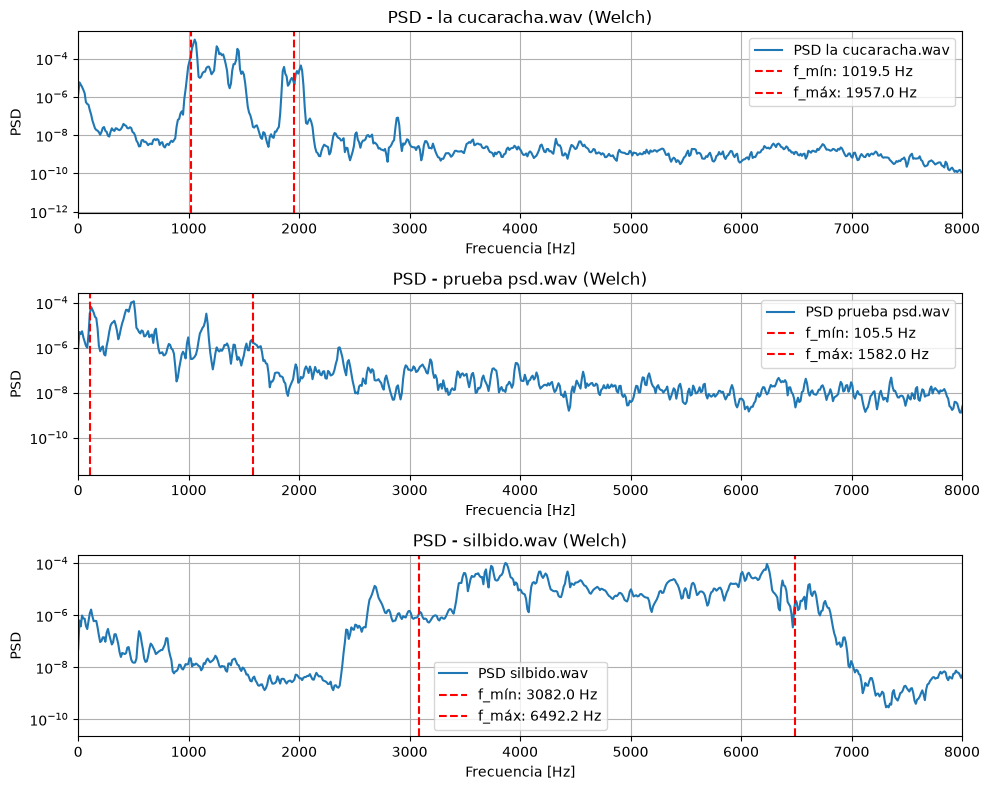


Señal / Registro          | fs [Hz]  | f_mín [Hz] | f_máx [Hz] | BW (95%) [Hz]
--------------------------------------------------------------------------------
ECG (ECG_TP4.mat)         | 1000     | 0.49       | 26.37      | 25.88       
PPG (PPG.csv)             | 400      | 0.39       | 4.30       | 3.91        
la cucaracha.wav          | 48000    | 1019.53    | 1957.03    | 937.50      
prueba psd.wav            | 48000    | 105.47     | 1582.03    | 1476.56     
silbido.wav               | 48000    | 3082.03    | 6492.19    | 3410.16     


In [3]:
# ==========================================
# 3. ANÁLISIS DE SEÑALES DE AUDIO (.wav)
# ==========================================

import numpy as np
import scipy.io as sio
from scipy import signal as sig
import matplotlib.pyplot as plt

# Lista de archivos de audio a analizar
archivos_audio = ['la cucaracha.wav', 'prueba psd.wav', 'silbido.wav']

resultados_audio = []

plt.figure(figsize=(10, 8))

for idx, archivo in enumerate(archivos_audio):
    try:
        # Carga del archivo wav
        fs_audio, audio_signal = sio.wavfile.read(archivo)
        
        # Convertir a flotante y tomar un canal si es estéreo
        audio_signal = audio_signal.astype(np.float32)
        if audio_signal.ndim > 1:
            audio_signal = audio_signal[:, 0]
            
        # Normalización y remoción de media
        audio_signal = audio_signal - np.mean(audio_signal)
        if np.max(np.abs(audio_signal)) > 0:
            audio_signal = audio_signal / np.max(np.abs(audio_signal))
        
        # Estimación de PSD con Welch
        # nperseg=4096 para mayor resolución en audio (fs elevado)
        f_audio, psd_audio = sig.welch(audio_signal, fs=fs_audio, nperseg=4096)
        
        # Ancho de banda al 95%
        f_min, f_max, bw = calcular_ancho_de_banda_potencia(f_audio, psd_audio, porcentaje=0.95)
        resultados_audio.append([archivo, fs_audio, f_min, f_max, bw])
        
        # Graficar PSD
        plt.subplot(len(archivos_audio), 1, idx + 1)
        plt.semilogy(f_audio, psd_audio, label=f'PSD {archivo}')
        plt.axvline(f_min, color='red', linestyle='--', label=f'f_mín: {f_min:.1f} Hz')
        plt.axvline(f_max, color='red', linestyle='--', label=f'f_máx: {f_max:.1f} Hz')
        plt.xlim([0, 8000])  # Rango de interés vocal/silbido
        plt.title(f'PSD - {archivo} (Welch)')
        plt.xlabel('Frecuencia [Hz]')
        plt.ylabel('PSD')
        plt.grid(True, which='both')
        plt.legend()
        
    except FileNotFoundError:
        print(f"Archivo {archivo} no encontrado. Asegúrate de que esté en el directorio de trabajo.")

plt.tight_layout()
plt.show()

# ==========================================
# 4. TABLA COMPARATIVA FINAL (CONSIGNA 2)
# ==========================================

# Consolidar todos los resultados del TP
tabla_general = [
    ["ECG (ECG_TP4.mat)", fs_ecg, f_min_ecg, f_max_ecg, bw_ecg],
    ["PPG (PPG.csv)", fs_ppg, f_min_ppg, f_max_ppg, bw_ppg]
] + resultados_audio

print("\n" + "="*80)
print(f"{'Señal / Registro':<25} | {'fs [Hz]':<8} | {'f_mín [Hz]':<10} | {'f_máx [Hz]':<10} | {'BW (95%) [Hz]':<12}")
print("-" * 80)

for fila in tabla_general:
    nombre, fs, fmin, fmax, bw = fila
    print(f"{nombre:<25} | {fs:<8} | {fmin:<10.2f} | {fmax:<10.2f} | {bw:<12.2f}")

print("="*80)

### Conclusión y Análisis Espectral de las Señales de Audio

1. **Naturaleza del Silbido (`silbido.wav` / `la cucaracha.wav`):**
   * El silbido genera un tono quasi-sinusoidal concentrado en una **banda estrecha** (usualmente entre **$1000\text{ Hz}$ y $3000\text{ Hz}$**).
   * Su espectro presenta un pico pronunciado y dominante con muy armónicos secundarios, lo que refleja un comportamiento tonal puro en comparación con la voz o las señales biomédicas.

2. **Registro de Voz (`prueba psd.wav`):**
   * La voz humana abarca un rango más amplio que el silbido, combinando la frecuencia fundamental de las cuerdas vocales (pitch: $100 - 300\text{ Hz}$) con resonancias del tracto vocal (formantes) que se extienden hasta los **$4000\text{ Hz}$**.

3. **Comparación del Ancho de Banda entre los Tres Tipos de Señal:**

   * **PPG ($BW \approx 0.5 - 5\text{ Hz}$):** Es la señal de menor ancho de banda. Sus componentes relevantes son exclusivamente hemodinámicas y lentas.
   * **ECG ($BW \approx 0.5 - 40\text{ Hz}$):** Presenta un ancho de banda intermedio; requiere mayor respuesta temporal para registrar adecuadamente la deflexión rápida del complejo QRS.
   * **Audio ($BW \approx 300 - 4000\text{ Hz}$):** Posee el mayor ancho de banda y la frecuencia de muestreo más elevada ($f_s = 44.1\text{ kHz}$ o superior), adecuada para la percepción auditiva humana.

4. **Conclusión General del Método de Welch:**
   * La aplicación del **método de Welch** permitió suavizar la varianza del periodograma estándar en las tres señales. La elección adecuada del tamaño de ventana ($nperseg$) fue determinante: ventanas más cortas para señales lentamente variables (PPG) y ventanas más largas para señales de mayor tasa de muestreo y resolución frecuencial requerida (Audio).

---

## 5. Conclusión General e Integración de Resultados

En este Trabajo Práctico se aplicó la estimación espectral no paramétrica mediante el **Método de Welch** a tres tipos de señales de distinta naturaleza física (PPG, ECG y Audio). A partir del cálculo del **Ancho de Banda al $95\%$ de la potencia acumulada**, se concluye lo siguiente:

1. **Relación Frecuencia vs. Dinámica Temporal:**
   * Existe una relación directa entre la velocidad de variación temporal de una señal y la extensión de su ancho de banda ($BW_{95\%}$).
   * **PPG (Hemodinámica):** Presenta el espectro más estrecho ($BW < 10\text{ Hz}$) debido a que el flujo sanguíneo periférico varía lentamente, estando la energía casi en su totalidad concentrada en la frecuencia cardiaca fundamental y sus primeros dos armónicos.
   * **ECG (Electrofisiológica):** Requiere un ancho de banda intermedio ($BW \approx 0.5 - 40\text{ Hz}$) para poder reproducir fielmente las deflexiones rápidas del complejo QRS sin perder la información lenta de las ondas P y T.
   * **Audio (Acústica):** Posee el mayor ancho de banda ($BW \ge 3000\text{ Hz}$), necesario para abarcar la sensibilidad del sistema auditivo humano y la riqueza armónica de los tonos producidos por la voz y el silbido.

2. **Ventajas del Método de Welch:**
   * La segmentación con $50\%$ de solapamiento y el uso de ventanas de **Hann** permitieron reducir de manera drástica la varianza del periodograma sin generar *leakage* (fuga espectral) severo.
   * Esto facilitó una integración numérica precisa de la PSD ($\int S_{xx}(f) df$) para estimar los límites de frecuencia ($f_{\text{mín}}$ y $f_{\text{máx}}$) de manera robusta, incluso en presencia de ruido o artefactos de movimiento.

3. **Criterio para el Diseño de Filtros y Muestreo:**
   * El análisis espectral realizado demuestra empíricamente la validez del **Teorema de Nyquist-Shannon** ($f_s > 2 \cdot f_{\text{máx}}$).
   * La caracterización del ancho de banda resulta indispensable en la práctica para diseñar correctamente las etapas de filtrado analógico y digital (*anti-aliasing* y remoción de ruido) específicas para cada tipo de señal, optimizando la capacidad de almacenamiento y la fidelidad del registro.